# HistGradientBoosting: enero–marzo de 2025

Pasamos de una semana a **90 reportes diarios consecutivos**. Conservamos el piloto
anterior y sus resultados. Este notebook compara las mismas variantes sin cambiar
sus hiperparámetros, y evalúa después HGB con NaN nativos y persistencia en una
semana final reservada de antemano. No se generan mediciones sintéticas.

**Alcance:** pronósticos históricos puntuales por estación conocida a 1, 24, 48 y
72 horas. No es una curva completa emitida desde un único origen, un modelo por
barrio ni un pronóstico actual. Un trimestre no cubre todas las temporadas del año.
La calidad final de los datos publicados por RMCAB no ha sido certificada aquí.

Para reconstruir el lote desde los reportes oficiales, con caché y descargas
secuenciales (comando externo al notebook; máximo 92 días por lote):

```bash
python -B -m research.collect_rmcab_period --start 2025-01-01 --end 2025-03-31 --network --output data/samples/rmcab_2025_q1.csv
```

Si ya hay caché para todas las fechas, omite `--network`. Los reportes válidos sin
mediciones se conservan con NaN. Un error de fecha/formato/unidad impide publicar
el lote completo y permite reanudar desde las descargas correctas. Todas las celdas
del notebook funcionan sin red con el CSV y manifiesto incluidos.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'research').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'research').is_dir():
    raise RuntimeError('Ejecuta desde la raíz del repositorio o notebooks/.')
sys.path.insert(0, str(ROOT))
from dash2.rmcab_data import load_samples
from research.air_quality import VARIABLES
from research.forecast_experiment import MODEL_PARAMS, feature_columns, run_pilot_benchmark

DATA_PATH = ROOT / 'data/samples/rmcab_2025_q1.csv'
PILOT_PATH = ROOT / 'data/samples/rmcab_pilot_2015_2025.csv'
LEGACY_PATH = ROOT / 'dash2/datasets/final_rutes.csv'
original_hashes = {path.relative_to(ROOT).as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
                   for path in (DATA_PATH, PILOT_PATH, LEGACY_PATH)}
source_hash = hashlib.sha256(DATA_PATH.with_suffix('.sources.json').read_bytes()).hexdigest()
started = datetime.now(timezone.utc).isoformat()
data = load_samples(DATA_PATH)
versions = {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']}
expected_days = pd.date_range('2025-01-01', '2025-03-31')
assert set(data.report_date.unique()) == set(expected_days), 'Falta algún reporte diario del trimestre.'
display(pd.Series(versions, name='version'))

numpy           1.26.4
pandas           2.3.3
scikit-learn     1.7.2
matplotlib      3.10.7
Name: version, dtype: object

## 1. Fechas y métodos fijados antes de puntuar

- **Desarrollo:** reportes del 1 de enero al 21 de marzo. Tres ventanas semanales
  de evaluación, con entrenamiento creciente y purga de etiquetas futuras.
- **Evaluación final:** objetivos observados de los reportes del 25 al 31 de marzo.
  Cada horizonte usa orígenes anteriores según su antelación. Solo se compara el
  HGB con NaN nativos, elegido para esta versión antes de ver sus resultados, con
  la referencia de persistencia. No se seleccionan parámetros con esta semana.
- Se exigen 28 días distintos de horas de origen y 2.000 filas para entrenar cada
  corte. Es un umbral operativo, no una garantía estadística de suficiencia.

Se respetan las horas 01–24 del portal: la hora 24 es la medianoche siguiente. Las
ventanas de origen cambian con el horizonte, pero los objetivos de la prueba final
pertenecen a los mismos siete reportes. Todas las etiquetas de entrenamiento están
antes del primer origen de su ventana de evaluación, incluidas las de otras estaciones.

La semana final permanece separada de la comparación de variantes. Una vez que se
consultan sus resultados deja de ser un test nuevo para cambios futuros: cualquier
ajuste posterior necesitará otro periodo final. El mes de abril aún no forma parte
de este experimento. No se hace selección automática del ganador.

In [2]:
BASE_CONFIG = dict(targets=('pm_25', 'pm_10'), horizons=(1, 24, 48, 72),
                   validation_hours=7 * 24, min_train_hours=28 * 24, min_train_rows=2000)
DEVELOPMENT_METHODS = ('persistence', 'hgb_native_missing', 'hgb_train_median')
FINAL_METHODS = ('persistence', 'hgb_native_missing')
development_data = data.loc[data.report_date.le('2025-03-21')].copy()
display(pd.Series(MODEL_PARAMS, name='HGB_parameter_frozen'))
print('Reportes de desarrollo:', development_data.report_date.nunique())
print('Objetivos finales reservados: reportes 2025-03-25 a 2025-03-31')

max_iter                80
max_leaf_nodes          15
min_samples_leaf        20
learning_rate         0.05
l2_regularization      1.0
early_stopping       False
random_state            42
Name: HGB_parameter_frozen, dtype: object

Reportes de desarrollo: 80
Objetivos finales reservados: reportes 2025-03-25 a 2025-03-31


## 2. Cobertura y ausencias

Tener los 90 reportes no significa que todas las estaciones midan todas las
variables durante cada hora. Se muestran las ausencias reales; no se sustituyen
por cero. Las fechas aisladas de 2015–2024 permanecen en el piloto y no se mezclan
como si fueran horas consecutivas de este trimestre.

In [3]:
monthly = data.groupby(data.report_date.dt.to_period('M')).agg(
    report_days=('report_date', 'nunique'), station_hours=('datetime', 'size'),
    PM25_observed=('pm_25', 'count'), PM10_observed=('pm_10', 'count'),
    temperature_observed=('temperature', 'count'), humidity_observed=('humidity', 'count'))
display(monthly)
coverage = data.groupby(['station_id', 'station_name']).agg(
    listed_station_hours=('datetime', 'size'), pm25_observed=('pm_25', 'count'),
    pm10_observed=('pm_10', 'count'), temperature_observed=('temperature', 'count'),
    humidity_observed=('humidity', 'count')).reset_index()
display(coverage)
print('Intervalo horario:', data.datetime.min(), 'a', data.datetime.max())
print('Los reportes diarios y sus hashes están en', DATA_PATH.with_suffix('.sources.json').relative_to(ROOT))
daily_coverage = data.groupby('report_date').agg(station_hours=('datetime', 'size'),
                                              pm25_observed=('pm_25', 'count'), pm10_observed=('pm_10', 'count'))
days_without_pm = daily_coverage.loc[(daily_coverage.pm25_observed + daily_coverage.pm10_observed).eq(0)].index
print('Reportes válidos sin ninguna medición PM:', days_without_pm.strftime('%Y-%m-%d').tolist())


,report_days,station_hours,PM25_observed,PM10_observed,temperature_observed,humidity_observed
report_date,,,,,,
2025-01,31,14136,7291,7501,10901,7940
2025-02,28,12768,11145,11648,10076,7367
2025-03,31,14136,12341,13126,11160,8182


,station_id,station_name,listed_station_hours,pm25_observed,pm10_observed,temperature_observed,humidity_observed
0,1,usaquen,2160,1017,1797,2160,0
1,11,suba,2160,1672,1598,2160,0
2,13,puente aranda,2160,1480,1515,0,2160
3,17,minambiente,2160,1837,1848,0,0
4,24,san cristobal,2160,1597,1556,2160,2160
5,26,movil 7ma,2160,1763,1770,2159,2160
6,27,bolivia,2160,1609,2026,2159,2159
7,3,carvajal - sevillana,2160,1054,1026,2160,0
8,30,fontibon,2160,1644,1698,1916,1916
9,32,usme,2160,1603,1642,2145,0


Intervalo horario: 2025-01-01 01:00:00-05:00 a 2025-04-01 00:00:00-05:00
Los reportes diarios y sus hashes están en data\samples\rmcab_2025_q1.sources.json
Reportes válidos sin ninguna medición PM: ['2025-01-27', '2025-01-28']


## 3. Comparación durante desarrollo

Mismas entradas que en el piloto: estación, las cuatro variables disponibles en el
origen, rezagos exactos del objetivo a 1/24 h, hora y mes cíclicos, día de semana.
Se requiere el contaminante actual observado para comparar todos los métodos en
las mismas filas. El objetivo futuro siempre es observado, nunca imputado.

HGB trata NaN de forma nativa; la variante con mediana ajusta el imputador solo
con el entrenamiento del corte. La parada temprana está desactivada para evitar
una validación aleatoria interna. No se usa meteorología observada en el futuro.

Los modelos se ajustan al inicio de cada ventana y evalúan cada punto usando sus
entradas disponibles en el origen correspondiente. La disponibilidad inmediata de
los datos publicados se presupone: no tenemos un archivo de retrasos/revisiones.
Se evalúa generalización temporal de estaciones conocidas, no extrapolación espacial.

In [4]:
development = run_pilot_benchmark(development_data, **BASE_CONFIG, n_folds=3, methods=DEVELOPMENT_METHODS)
display(development['scores'].round(3))
display(development['folds'][['target', 'horizon_hours', 'fold', 'train_rows',
                              'train_origin_hours', 'validation_rows', 'status']])
assert development['folds'].status.eq('evaluated').all(), 'Revisar cualquier ventana omitida.'

,target,horizon_hours,method,n,MAE_ug_m3,RMSE_ug_m3,baseline_MAE,MAE_skill_vs_persistence
0,pm_10,1,hgb_native_missing,8726,7.140,9.966,7.501,0.048
1,pm_10,1,hgb_train_median,8726,7.132,9.952,7.501,0.049
2,pm_10,1,persistence,8726,7.501,10.782,7.501,0.000
3,pm_10,24,hgb_native_missing,8661,13.613,17.764,16.154,0.157
4,pm_10,24,hgb_train_median,8661,13.699,17.875,16.154,0.152
5,pm_10,24,persistence,8661,16.154,22.076,16.154,0.000
6,pm_10,48,hgb_native_missing,8637,14.448,18.602,17.692,0.183
7,pm_10,48,hgb_train_median,8637,14.427,18.603,17.692,0.185
8,pm_10,48,persistence,8637,17.692,23.326,17.692,0.000
9,pm_10,72,hgb_native_missing,8612,15.049,19.267,17.958,0.162


,target,horizon_hours,fold,train_rows,train_origin_hours,validation_rows,status
0,pm_25,1,1,18308,1317,2786,evaluated
1,pm_25,1,2,21096,1485,2611,evaluated
2,pm_25,1,3,23706,1653,2841,evaluated
3,pm_25,24,1,16847,1248,2722,evaluated
4,pm_25,24,2,19569,1416,2518,evaluated
5,pm_25,24,3,22085,1584,2837,evaluated
6,pm_25,48,1,15497,1176,2635,evaluated
7,pm_25,48,2,18094,1344,2447,evaluated
8,pm_25,48,3,20600,1512,2822,evaluated
9,pm_25,72,1,14238,1104,2535,evaluated


## 4. Semana final reservada

Entrenamos las mismas configuraciones fijas con el pasado disponible en cada corte
final y evaluamos sin elegir una nueva variante sobre sus resultados. MAE y RMSE
se expresan en µg/m³; menor es mejor. El índice de mejora frente a persistencia
es positivo cuando HGB reduce el MAE; no es un porcentaje de exactitud.

Los cortes de entrenamiento varían según el horizonte. Los días 22–24 de marzo
pueden aportar entradas o lecturas anteriores al origen correspondiente, siempre
fuera de los objetivos finales reservados y respetando la purga temporal.

In [5]:
holdout = run_pilot_benchmark(data, **BASE_CONFIG, n_folds=1, methods=FINAL_METHODS)
assert holdout['folds'].status.eq('evaluated').all()
assert set(holdout['predictions'].method) == set(FINAL_METHODS)
final_predictions = holdout['predictions']
assert final_predictions.target_datetime.gt(pd.Timestamp('2025-03-25', tz='America/Bogota')).all()
assert final_predictions.target_datetime.le(pd.Timestamp('2025-04-01', tz='America/Bogota')).all()
for experiment in (development, holdout):
    evaluated = experiment['folds'].loc[experiment['folds'].status.eq('evaluated')]
    assert (evaluated.train_target_max < evaluated.validation_origin_start).all()
display(holdout['scores'].round(3))
summary = holdout['scores'].pivot(index=['target', 'horizon_hours'], columns='method', values='MAE_ug_m3')
summary['HGB_improves_MAE'] = summary.hgb_native_missing < summary.persistence
display(summary.round(3))

,target,horizon_hours,method,n,MAE_ug_m3,RMSE_ug_m3,baseline_MAE,MAE_skill_vs_persistence
0,pm_10,1,hgb_native_missing,2966,7.330,10.562,8.066,0.091
1,pm_10,1,persistence,2966,8.066,11.570,8.066,0.000
2,pm_10,24,hgb_native_missing,2972,12.366,17.520,15.424,0.198
3,pm_10,24,persistence,2972,15.424,21.693,15.424,0.000
4,pm_10,48,hgb_native_missing,2974,13.789,19.108,19.268,0.284
5,pm_10,48,persistence,2974,19.268,26.506,19.268,0.000
6,pm_10,72,hgb_native_missing,2970,14.203,19.902,20.448,0.305
7,pm_10,72,persistence,2970,20.448,27.902,20.448,0.000
8,pm_25,1,hgb_native_missing,2854,4.180,5.557,4.892,0.146
9,pm_25,1,persistence,2854,4.892,6.558,4.892,0.000


method                hgb_native_missing  persistence  HGB_improves_MAE
target horizon_hours                                                   
pm_10  1                           7.330        8.066              True
       24                         12.366       15.424              True
       48                         13.789       19.268              True
       72                         14.203       20.448              True
pm_25  1                           4.180        4.892              True
       24                          6.487        8.000              True
       48                          7.382        9.407              True
       72                          7.613        9.399              True

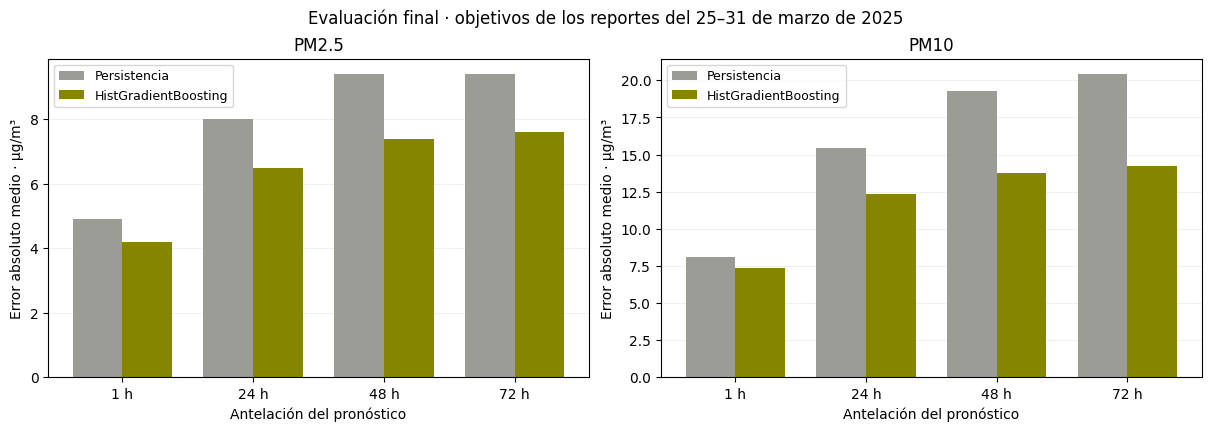

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for ax, target, label in zip(axes, ('pm_25', 'pm_10'), ('PM2.5', 'PM10')):
    rows = summary.loc[target].sort_index()
    x = np.arange(len(rows))
    ax.bar(x - 0.19, rows.persistence, width=0.38, color='#9c9c96', label='Persistencia')
    ax.bar(x + 0.19, rows.hgb_native_missing, width=0.38, color='#858500', label='HistGradientBoosting')
    ax.set_xticks(x, [f'{h} h' for h in rows.index])
    ax.set(title=label, ylabel='Error absoluto medio · µg/m³', xlabel='Antelación del pronóstico')
    ax.grid(axis='y', alpha=0.18)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)
fig.suptitle('Evaluación final · objetivos de los reportes del 25–31 de marzo de 2025')
plt.show()

## 5. Variación por estación y por ventana

El promedio global puede ocultar estaciones donde el modelo empeora. Se conservan
las métricas por estación y por ventana. No se eliminan estaciones ni se ajustan
hiperparámetros después de ver el test final.

In [7]:
station_comparison = holdout['per_station'].pivot(index=['target', 'horizon_hours', 'station_id', 'station_name'],
                                                columns='method', values='MAE_ug_m3')
station_comparison['HGB_improves_MAE'] = station_comparison.hgb_native_missing < station_comparison.persistence
display(station_comparison.groupby(['target', 'horizon_hours']).agg(
    stations=('HGB_improves_MAE', 'size'), stations_improved=('HGB_improves_MAE', 'sum')))
display(station_comparison.round(3).head(20))
from research.forecast_experiment import summarize_predictions
development_by_fold = summarize_predictions(development['predictions'], ['target', 'horizon_hours', 'fold', 'method'])
display(development_by_fold.round(3))

stations  stations_improved
target horizon_hours                             
pm_10  1                    18                 18
       24                   18                 18
       48                   18                 18
       72                   18                 18
pm_25  1                    17                 17
       24                   17                 17
       48                   17                 16
       72                   17                 17

method                                                      hgb_native_missing  \
target horizon_hours station_id station_name                                     
pm_10  1             1          usaquen                                  8.109   
                     11         suba                                     7.360   
                     13         puente aranda                            6.855   
                     17         minambiente                              9.374   
                     24         san cristobal                            8.250   
                     26         movil 7ma                               10.485   
                     27         bolivia                                  6.216   
                     30         fontibon                                 6.207   
                     32         usme                                    11.049   
                     34         jazmin                                   5.793   
                     37         ciudad bolivar                           6.260   
                     38         colina                                   4.037   
                     39         movil fontibon                           8.207   
                     4          tunal                                   11.768   
                     5          centro de alto rendimiento               5.013   
                     6          las ferias                               4.474   
                     8          guaymaral                                6.438   
                     9          kennedy                                  5.935   
       24            1          usaquen                                 11.501   
                     11         suba                                    13.626   

method                                                      persistence  \
target horizon_hours station_id station_name                              
pm_10  1             1          usaquen                           8.775   
                     11         suba                              8.925   
                     13         puente aranda                     7.946   
                     17         minambiente                      10.873   
                     24         san cristobal                     9.319   
                     26         movil 7ma                        11.738   
                     27         bolivia                           6.711   
                     30         fontibon                          6.744   
                     32         usme                             11.340   
                     34         jazmin                            6.384   
                     37         ciudad bolivar                    6.290   
                     38         colina                            4.415   
                     39         movil fontibon                    8.626   
                     4          tunal                            12.723   
                     5          centro de alto rendimiento        5.377   
                     6          las ferias                        4.843   
                     8          guaymaral                         7.500   
                     9          kennedy                           6.613   
       24            1          usaquen                          13.354   
                     11         suba                             14.584   

method                                                      HGB_improves_MAE  
target horizon_hours station_id station_name                                  
pm_10  1             1          usaquen                                 True  
                     11         suba                                    True  
                     13         puente aranda                           True  
                     17         minambiente                             True  
                     24         san cristobal                         

,target,horizon_hours,fold,method,n,MAE_ug_m3,RMSE_ug_m3
0,pm_10,1,1,hgb_native_missing,2996,7.576,10.810
1,pm_10,1,1,hgb_train_median,2996,7.564,10.766
2,pm_10,1,1,persistence,2996,8.229,11.838
3,pm_10,1,2,hgb_native_missing,2815,7.439,10.447
4,pm_10,1,2,hgb_train_median,2815,7.408,10.438
...,...,...,...,...,...,...,...
67,pm_25,72,2,hgb_train_median,2431,8.465,10.586
68,pm_25,72,2,persistence,2431,10.234,13.190
69,pm_25,72,3,hgb_native_missing,2777,10.943,12.583
70,pm_25,72,3,hgb_train_median,2777,11.002,12.643


## 6. Informes, reproducibilidad y siguiente decisión

Los resultados se guardan con hash de entrada, versiones y parámetros. Las
predicciones detalladas conservan URL/hash de su observación objetivo y quedan en
`data/processed/` como salida regenerable. No se cambian las mediciones del piloto,
el CSV histórico anterior ni el dataset que consume Dash.

No exportamos un artefacto de producción desde esta evaluación. La decisión de
avanzar depende de los errores observados, su variación por estación/horizonte,
la cobertura y la disponibilidad real de entradas recientes. Para probar cambios
posteriores se necesita otro periodo de test; para afirmar comportamiento anual,
datos de otras temporadas. La estimación por barrios requiere validación espacial.

Referencias:
- [RMCAB: reportes horarios oficiales](https://rmcab.ambientebogota.gov.co/Report/HourlyReports)
- [HGB y entradas faltantes](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html)
- [Rezagos y evaluación temporal](https://scikit-learn.org/1.7/auto_examples/applications/plot_time_series_lagged_features.html)

In [8]:
REPORTS = ROOT / 'data/reports/hgb_2025_q1'
PROCESSED = ROOT / 'data/processed'
REPORTS.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
for phase, experiment in [('development', development), ('holdout', holdout)]:
    for name in ('scores', 'folds', 'per_station'):
        experiment[name].to_csv(REPORTS / f'{phase}_{name}.csv', index=False, lineterminator="\n")
    experiment['predictions'].to_csv(PROCESSED / f'hgb_2025_q1_{phase}_predictions.csv', index=False, lineterminator="\n")
development_by_fold.to_csv(REPORTS / 'development_scores_by_fold.csv', index=False, lineterminator="\n")
coverage.to_csv(REPORTS / 'observed_coverage_by_station.csv', index=False, lineterminator="\n")
monthly.to_csv(REPORTS / 'observed_coverage_by_month.csv', lineterminator="\n")
daily_coverage.to_csv(REPORTS / 'observed_coverage_by_day.csv', lineterminator="\n")
fig.savefig(REPORTS / 'holdout_mae.png', dpi=150, bbox_inches='tight')
for relative, digest in original_hashes.items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == digest
metadata = dict(
    experiment='hgb_2025_q1_frozen_v1', started_at_utc=started, versions=versions,
    input_sha256=original_hashes, source_manifest_sha256=source_hash,
    valid_report_dates_without_pm=days_without_pm.strftime('%Y-%m-%d').tolist(),
    report_days=int(data.report_date.nunique()), station_hours=len(data), stations=int(data.station_id.nunique()),
    development_report_end='2025-03-21', final_target_report_start='2025-03-25', final_target_report_end='2025-03-31',
    base_config=BASE_CONFIG, development_methods=DEVELOPMENT_METHODS, final_methods=FINAL_METHODS,
    hgb_parameters=MODEL_PARAMS, feature_columns={t: feature_columns(t) for t in BASE_CONFIG['targets']},
    development_evaluated_folds=int(development['folds'].status.eq('evaluated').sum()),
    holdout_evaluated_folds=int(holdout['folds'].status.eq('evaluated').sum()),
    negative_holdout_hgb_predictions=int(final_predictions.loc[final_predictions.method.eq('hgb_native_missing'), 'y_pred'].lt(0).sum()),
    synthetic_observations_created=0, source_measurements_modified=False,
    final_method_fixed_before_evaluation=True, hyperparameter_search=False,
    deployment_ready=False, artifact_exported=False,
    limitation='One quarter; known-station retrospective point forecasts; published availability assumed; source final QC unverified; no annual/spatial/live validation; holdout now consumed for future changes.',
)
(REPORTS / 'experiment.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8', newline="\n")
print('Informes guardados:', REPORTS.relative_to(ROOT))
print('Ventanas de desarrollo:', metadata['development_evaluated_folds'], '| finales:', metadata['holdout_evaluated_folds'])
print('CSV originales intactos. No hay registros sintéticos ni un modelo desplegado.')

Informes guardados: data\reports\hgb_2025_q1
Ventanas de desarrollo: 24 | finales: 8
CSV originales intactos. No hay registros sintéticos ni un modelo desplegado.
